# Filtre passe-bas : moyenne mobile et lissage exponentiel

**Projet EGALIZE — étude n° 1**

Objectif : implémenter **à la main**, sans bibliothèque de filtrage, les deux passe-bas les plus simples, puis les appliquer à un signal de test.

| Partie | Contenu |
|---|---|
| 0 | Préparation : bibliothèques, paramètres, petits outils |
| 1 | Synthétiser un signal connu : une note grave, une médium, une aiguë |
| 2 | Filtre n° 1 : la **moyenne mobile** |
| 3 | Filtre n° 2 : le **lissage exponentiel** |
| 4 | Comparer avant / après : temps, fréquences, mesures, écoute |
| 5 | Appliquer un **gain** à la bande des graves |

> **Rappel de l'idée :** un passe-bas **fait des moyennes**. Les variations lentes (graves) survivent, les variations rapides (aigus) s'annulent.

**Mode d'emploi :** exécutez les cellules dans l'ordre (menu **Exécuter tout**). Chaque cellule de code est précédée d'une note qui dit ce qu'elle fait.

## 0. Préparation

> **Ce que fait la cellule suivante :** elle importe les bibliothèques, fixe les **paramètres** de l'étude et définit de **petits outils** réutilisés dans tout le notebook :

- `spectre_db` calcule le spectre d'un signal (FFT) en décibels ;
- `amplitude_a` lit l'amplitude d'**une** note précise dans ce spectre ;
- `en_db` convertit un rapport d'amplitudes en dB ;
- `axe_frequences` met en forme l'axe des fréquences des graphiques ;
- `ecouter` crée un lecteur audio **sans normalisation**, pour entendre le vrai niveau.

Seuls `FC` (fréquence de coupure) et `DUREE` sont intéressants à modifier.

In [1]:
%matplotlib inline
import numpy as np                    # calcul numérique (tableaux, sinus, FFT…)
import pandas as pd                   # tableaux de résultats
import matplotlib.pyplot as plt       # graphiques
from IPython.display import Audio, display   # lecteurs audio dans le notebook

# --- Paramètres de l'étude ----------------------------------------------------
FS = 44_100      # fréquence d'échantillonnage (Hz) : 44 100 échantillons par seconde, comme la piste du projet
DUREE = 2.0      # durée du signal de test (s)
FC = 250.0       # fréquence de coupure visée (Hz) : la frontière graves / médiums d'EGALIZE

# --- Couleurs (thème EGALIZE) et style des graphiques --------------------------
NUIT, BLEU, OR, VIOLET, GRIS = "#0b1a33", "#1f5bff", "#c58c12", "#7c5cff", "#9aa6bb"
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "legend.fontsize": 9,
})


def spectre_db(signal):
    # Spectre d'amplitude en dB, calculé par FFT (transformée de Fourier rapide).
    # - np.fft.rfft donne un nombre complexe par fréquence ; son module = « quantité » de cette fréquence.
    # - On multiplie par 2/N pour retrouver l'amplitude de chaque sinusoïde (0,30 pour la grave, etc.).
    # - Le signal contient un nombre entier de périodes de chaque note : chaque note tombe pile
    #   sur une case de la FFT, ce qui rend la lecture exacte.
    N = len(signal)
    amplitudes = 2 * np.abs(np.fft.rfft(signal)) / N
    frequences = np.fft.rfftfreq(N, 1 / FS)          # fréquence (Hz) de chaque case
    return frequences, 20 * np.log10(np.maximum(amplitudes, 1e-6))   # 1e-6 évite log(0)


def amplitude_a(signal, f):
    # Amplitude de la note de fréquence f : on lit la case numéro k = f × N / FS de la FFT.
    N = len(signal)
    k = int(round(f * N / FS))
    return 2 * np.abs(np.fft.rfft(signal)[k]) / N


def en_db(rapport):
    # Rapport d'amplitudes -> décibels : 0,5 -> −6 dB ; 2 -> +6 dB ; 1 -> 0 dB.
    return 20 * np.log10(rapport)


def axe_frequences(ax):
    # Axe des fréquences en échelle logarithmique (chaque octave a la même largeur, comme à l'oreille).
    ticks = [20, 50, 100, 200, 500, 1000, 2000, 5000, 10000, 20000]
    ax.set_xscale("log")
    ax.set_xlim(20, FS / 2)                          # de 20 Hz à la fréquence de Nyquist (FS / 2)
    ax.set_xticks(ticks, ["20", "50", "100", "200", "500", "1k", "2k", "5k", "10k", "20k"])
    ax.set_xlabel("Fréquence (Hz, échelle logarithmique)")


def ecouter(signal, titre):
    # Lecteur audio SANS normalisation : on entend le niveau réel du signal.
    # Un échantillon ne peut pas dépasser ±1 (0 dBFS) : au-delà, le son serait écrêté (distordu).
    crete = np.max(np.abs(signal))
    print(f"{titre} — crête : {crete:.2f} ({en_db(crete):.1f} dBFS)")
    if crete > 1:
        print("  ⚠ Le signal dépasse 1 (0 dBFS) : il écrêterait. Lecture refusée.")
        return
    display(Audio(signal, rate=FS, normalize=False))

## 1. Synthétiser un signal de test

On fabrique un signal **dont on connaît tout** : la somme de trois sinusoïdes, une par bande de l'égaliseur.

$$x(t) = A_g \sin(2\pi f_g t) + A_m \sin(2\pi f_m t) + A_a \sin(2\pi f_a t)$$

| Composante | Fréquence | Amplitude | Bande d'EGALIZE |
|---|---|---|---|
| grave | 100 Hz | 0,30 | graves (< 250 Hz) |
| médium | 1 000 Hz | 0,20 | médiums |
| aigu | 5 000 Hz | 0,12 | aigus |

Avantage : après filtrage, on pourra **mesurer exactement** ce qu'est devenue chaque note.

> **Ce que fait la cellule suivante :** elle crée l'axe du temps (un instant par échantillon), calcule les trois sinusoïdes et les additionne pour obtenir le signal de test `x`.

In [2]:
# Axe du temps : n / FS pour n = 0, 1, 2, … (88 200 instants pour 2 s)
t = np.arange(int(DUREE * FS)) / FS

COMPOSANTES = {                               # nom : (fréquence en Hz, amplitude)
    "Grave 100 Hz": (100, 0.30),
    "Médium 1 kHz": (1000, 0.20),
    "Aigu 5 kHz": (5000, 0.12),
}

# Chaque note est une sinusoïde A·sin(2π f t)
sinusoides = {nom: A * np.sin(2 * np.pi * f * t) for nom, (f, A) in COMPOSANTES.items()}

# Le signal de test est leur somme
x = sum(sinusoides.values())

print(f"{len(x)} échantillons, {DUREE} s à {FS} Hz — crête : {np.max(np.abs(x)):.2f}")

88200 échantillons, 2.0 s à 44100 Hz — crête : 0.61


> **Ce que fait la cellule suivante :** elle trace le signal de deux façons. En haut, **dans le temps** : un zoom sur 20 ms avec chaque note en couleur et leur somme en noir. En bas, **dans les fréquences** : le spectre. Puis elle affiche un lecteur pour écouter le signal.

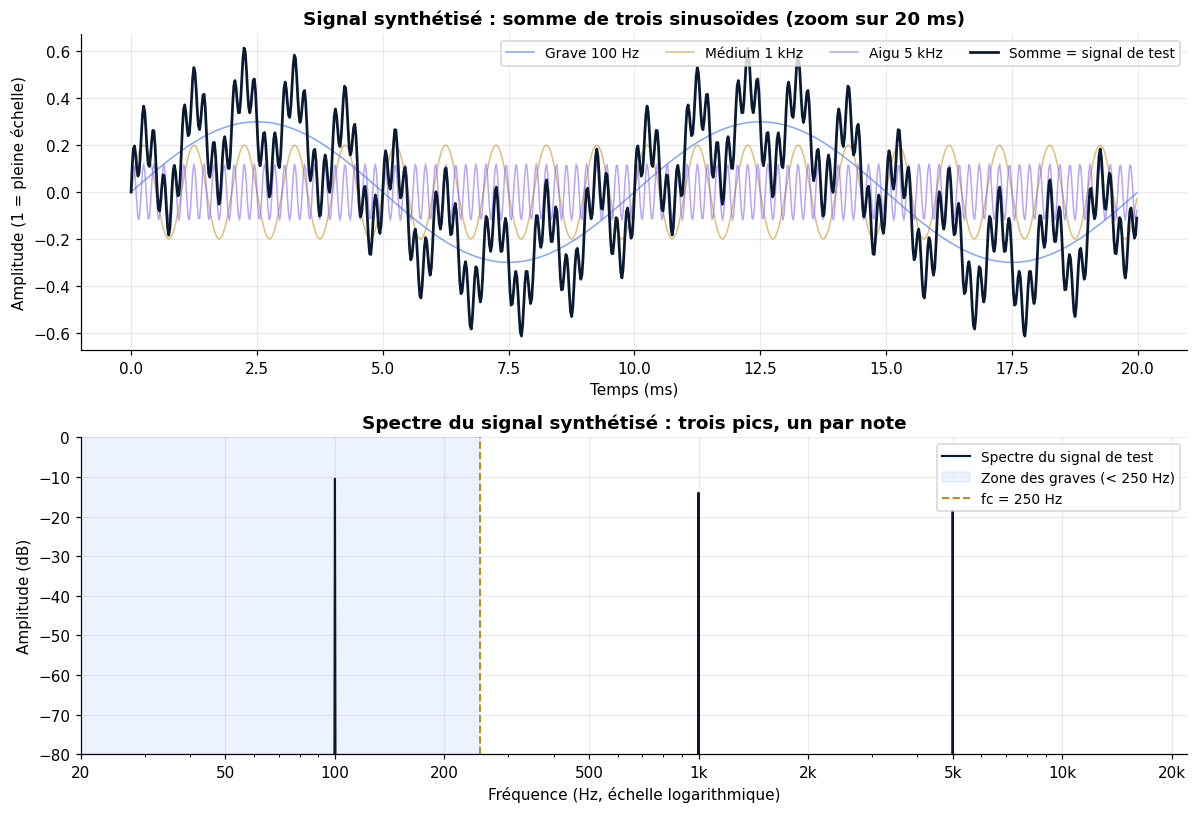

Signal de test — crête : 0.61 (-4.2 dBFS)


In [3]:
# Fenêtre de zoom : 20 ms prises au milieu du signal (loin du démarrage des filtres)
zoom = (t >= 0.5) & (t < 0.52)
t_ms = (t[zoom] - 0.5) * 1000                 # temps en millisecondes, à partir de 0

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7.5))

# Haut : chaque note (traits fins) et leur somme (trait épais)
for (nom, s), couleur in zip(sinusoides.items(), [BLEU, OR, VIOLET]):
    ax1.plot(t_ms, s[zoom], color=couleur, lw=1, alpha=0.55, label=nom)
ax1.plot(t_ms, x[zoom], color=NUIT, lw=1.8, label="Somme = signal de test")
ax1.set(title="Signal synthétisé : somme de trois sinusoïdes (zoom sur 20 ms)",
        xlabel="Temps (ms)", ylabel="Amplitude (1 = pleine échelle)")
ax1.legend(loc="upper right", ncol=4)

# Bas : le spectre, avec la zone des graves et la coupure
f, db = spectre_db(x)
ax2.plot(f[1:], db[1:], color=NUIT, lw=1.4, label="Spectre du signal de test")
ax2.axvspan(20, FC, color=BLEU, alpha=0.08, label="Zone des graves (< 250 Hz)")
ax2.axvline(FC, color=OR, ls="--", lw=1.3, label="fc = 250 Hz")
axe_frequences(ax2)
ax2.set(title="Spectre du signal synthétisé : trois pics, un par note",
        ylabel="Amplitude (dB)", ylim=(-80, 0))
ax2.legend(loc="upper right")
fig.tight_layout()
plt.show()

ecouter(x, "Signal de test")

> **Comment lire le résultat :** en haut, la grande ondulation lente est la **grave** (2 périodes en 20 ms). Les petites oscillations rapides posées dessus sont la **médium** et l'**aiguë**. En bas, chaque note donne un **pic** à sa fréquence. Seul le pic de 100 Hz est dans la zone bleue des graves : c'est lui que le passe-bas doit garder.

## 2. Filtre n° 1 : la moyenne mobile

**Principe :** chaque échantillon de sortie est la **moyenne des M derniers échantillons** d'entrée.

$$y[n] = \frac{x[n] + x[n-1] + \dots + x[n-M+1]}{M}$$

- Une variation **lente** ne change presque pas sur M échantillons : la moyenne la conserve.
- Une variation **rapide** fait plusieurs allers-retours dans la fenêtre : ses valeurs + et − s'annulent.

**Comment choisir M ?** Plus la fenêtre est longue, plus on moyenne, donc plus la coupure est basse. La théorie donne le gain de la moyenne mobile à la fréquence $f$ :

$$|H(f)| = \left| \frac{\sin(\pi f M / f_s)}{M \, \sin(\pi f / f_s)} \right|$$

On cherche le M qui donne $|H(f_c)| = 0{,}707$ (soit −3 dB) à $f_c = 250$ Hz.

> **Ce que fait la cellule suivante :** elle définit deux fonctions et les utilise :

1. `moyenne_mobile(x, M)` : le filtre lui-même. Plutôt que de refaire la somme des M valeurs à chaque pas, elle **ajoute l'échantillon qui entre** dans la fenêtre et **retire celui qui en sort**.
2. `gain_moyenne_mobile(f, M)` : la formule théorique ci-dessus.

Ensuite, elle **essaie toutes les longueurs M** de 2 à 999 et garde celle qui donne −3 dB à 250 Hz. Elle filtre le signal, puis vérifie que le résultat est identique à une **convolution**, l'opération mathématique qu'on a vue dans l'explication.

In [4]:
def moyenne_mobile(x, M):
    # y[n] = moyenne de x[n-M+1] … x[n].
    # Avant le M-ième échantillon, les valeurs manquantes (avant le début) comptent pour zéro.
    y = np.zeros_like(x)          # tableau de sortie, rempli de zéros au départ
    somme = 0.0                   # somme des échantillons présents dans la fenêtre
    for n in range(len(x)):
        somme += x[n]             # l'échantillon n entre dans la fenêtre…
        if n >= M:
            somme -= x[n - M]     # … et l'échantillon n-M en sort
        y[n] = somme / M          # moyenne = somme / nombre de valeurs
    return y


def gain_moyenne_mobile(f, M):
    # Gain théorique |H(f)| de la moyenne mobile de longueur M (formule ci-dessus).
    w = np.pi * np.asarray(f, dtype=float) / FS
    with np.errstate(invalid="ignore", divide="ignore"):
        h = np.abs(np.sin(M * w) / (M * np.sin(w)))
    return np.where(w == 0, 1.0, h)            # à 0 Hz, le gain vaut exactement 1


# Recherche de M : pour chaque longueur candidate, on calcule le gain à FC
# et on garde celle dont le gain est le plus proche de 0,707 (−3 dB).
candidats = np.arange(2, 1000)
M = int(candidats[np.argmin(np.abs(gain_moyenne_mobile(FC, candidats) - 1 / np.sqrt(2)))])
print(f"M = {M} échantillons, soit une fenêtre de {1000 * M / FS:.2f} ms")
print(f"Gain théorique à {FC:.0f} Hz : {float(gain_moyenne_mobile(FC, M)):.3f} ({en_db(gain_moyenne_mobile(FC, M)):.1f} dB)")

# Filtrage du signal de test
y_mm = moyenne_mobile(x, M)

# Vérification : la moyenne mobile est une convolution avec M coefficients égaux à 1/M
y_conv = np.convolve(x, np.ones(M) / M)[: len(x)]
print("Identique à la convolution avec np.convolve :", np.allclose(y_mm, y_conv))

M = 78 échantillons, soit une fenêtre de 1.77 ms
Gain théorique à 250 Hz : 0.708 (-3.0 dB)
Identique à la convolution avec np.convolve : True


> **Comment lire le résultat :** une fenêtre de **78 échantillons** (moins de 2 ms) suffit pour couper à 250 Hz. `True` confirme que notre boucle calcule bien une convolution.

## 3. Filtre n° 2 : le lissage exponentiel

**Principe :** la sortie **rattrape une fraction α de son retard** sur l'entrée, à chaque échantillon.

$$y[n] = y[n-1] + \alpha \,\big(x[n] - y[n-1]\big)$$

- α petit : la sortie rattrape lentement, elle ne suit que les variations lentes. La coupure est basse.
- α proche de 1 : la sortie suit presque tout. La coupure est haute.

C'est la version numérique du circuit RC (passe-bas d'ordre 1). La correspondance avec la fréquence de coupure est :

$$\alpha = 1 - e^{-2\pi f_c / f_s}$$

Ce filtre est **récursif** : il réutilise sa propre sortie précédente $y[n-1]$. Il n'a besoin que d'**une seule** valeur en mémoire. Son gain théorique :

$$|H(f)| = \left| \frac{\alpha}{1 - (1-\alpha)\, e^{-j 2\pi f / f_s}} \right|$$

> **Ce que fait la cellule suivante :** elle définit le filtre `lissage_exponentiel` et sa formule théorique `gain_lissage`, calcule α pour une coupure à 250 Hz, puis filtre le signal de test.

In [5]:
def lissage_exponentiel(x, alpha):
    # y[n] = y[n-1] + alpha * (x[n] - y[n-1]), en partant de y = 0.
    y = np.zeros_like(x)
    precedent = 0.0                                          # y[n-1] : la seule valeur gardée en mémoire
    for n in range(len(x)):
        ecart = x[n] - precedent                             # de combien la sortie est en retard
        precedent = precedent + alpha * ecart                # on rattrape une fraction alpha de ce retard
        y[n] = precedent
    return y


def gain_lissage(f, alpha):
    # Gain théorique |H(f)| du lissage exponentiel (formule ci-dessus, avec des nombres complexes).
    z = np.exp(-2j * np.pi * np.asarray(f, dtype=float) / FS)
    return np.abs(alpha / (1 - (1 - alpha) * z))


alpha = 1 - np.exp(-2 * np.pi * FC / FS)                     # α qui donne une coupure à FC
print(f"alpha = {alpha:.4f} : la sortie rattrape {100 * alpha:.1f} % de l'écart à chaque échantillon")
print(f"Gain théorique à {FC:.0f} Hz : {float(gain_lissage(FC, alpha)):.3f} ({en_db(gain_lissage(FC, alpha)):.1f} dB)")

y_exp = lissage_exponentiel(x, alpha)

alpha = 0.0350 : la sortie rattrape 3.5 % de l'écart à chaque échantillon
Gain théorique à 250 Hz : 0.707 (-3.0 dB)


> **Comment lire le résultat :** α ≈ 0,035 : à chaque échantillon, la sortie ne rattrape que 3,5 % de son retard. Elle est trop « lente » pour suivre la médium et l'aiguë, mais assez rapide pour suivre la grave.

## 4. Comparer avant / après filtrage

### 4.1 Dans le temps

> **Ce que fait la cellule suivante :** elle superpose, sur 20 ms : le signal d'origine (gris), la **grave seule** (pointillés noirs, c'est la cible idéale) et les sorties des deux filtres.

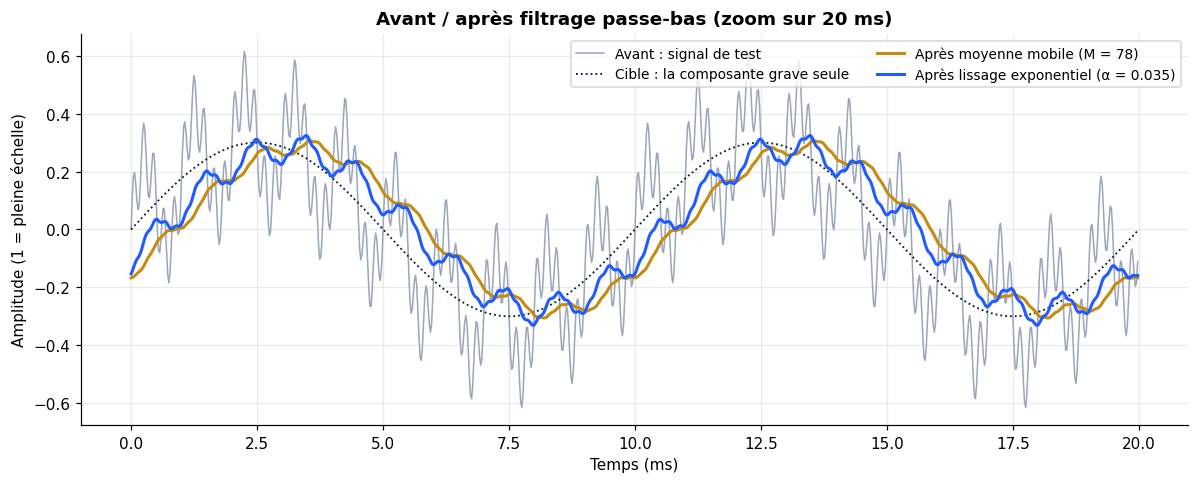

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(t_ms, x[zoom], color=GRIS, lw=1, label="Avant : signal de test")
ax.plot(t_ms, sinusoides["Grave 100 Hz"][zoom], color=NUIT, lw=1.2, ls=":", label="Cible : la composante grave seule")
ax.plot(t_ms, y_mm[zoom], color=OR, lw=2, label=f"Après moyenne mobile (M = {M})")
ax.plot(t_ms, y_exp[zoom], color=BLEU, lw=2, label=f"Après lissage exponentiel (α = {alpha:.3f})")
ax.set(title="Avant / après filtrage passe-bas (zoom sur 20 ms)", xlabel="Temps (ms)", ylabel="Amplitude (1 = pleine échelle)")
ax.legend(loc="upper right", ncol=2)
fig.tight_layout()
plt.show()

> **Comment lire le résultat :** les deux sorties sont **lisses** et suivent la grave, mais **légèrement en retard** sur elle. Ce retard est le **déphasage** du filtre : pour faire une moyenne, il faut attendre d'avoir vu les échantillons passés. Les petites ondulations qui restent sont la médium, **pas complètement supprimée**.

### 4.2 Dans les fréquences

> **Ce que fait la cellule suivante :** elle trace, à gauche, les spectres avant et après chaque filtre. À droite, elle résume l'amplitude de chaque note (en dB) sous forme de barres.

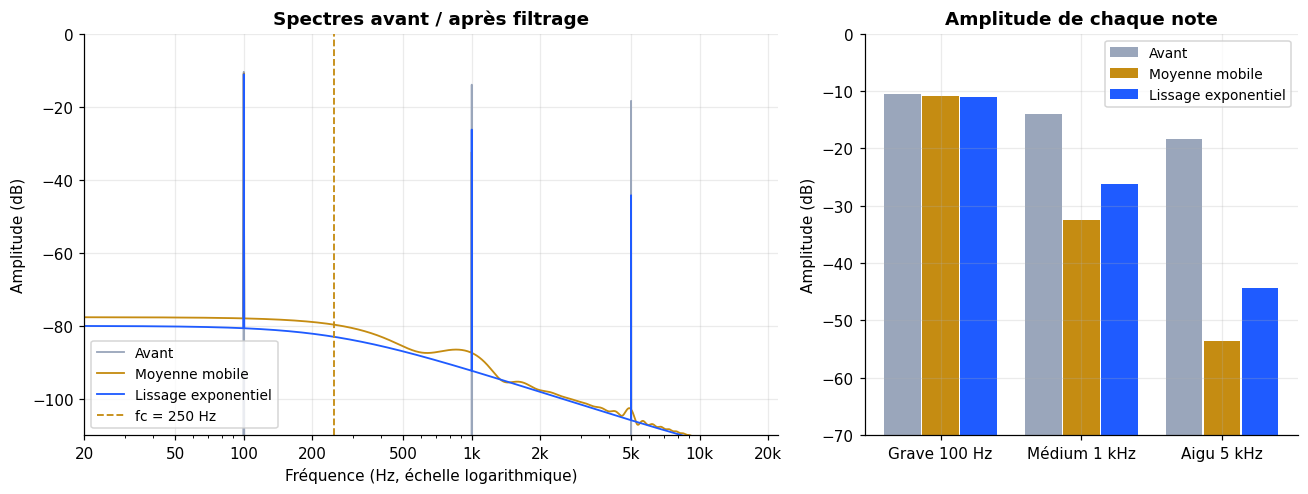

In [7]:
f, db_x = spectre_db(x)
_, db_mm = spectre_db(y_mm)
_, db_exp = spectre_db(y_exp)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.6, 1]})

# Gauche : spectres complets
ax1.plot(f[1:], db_x[1:], color=GRIS, lw=1.2, label="Avant")
ax1.plot(f[1:], db_mm[1:], color=OR, lw=1.2, label="Moyenne mobile")
ax1.plot(f[1:], db_exp[1:], color=BLEU, lw=1.2, label="Lissage exponentiel")
ax1.axvline(FC, color=OR, ls="--", lw=1.2, label="fc = 250 Hz")
axe_frequences(ax1)
ax1.set(title="Spectres avant / après filtrage", ylabel="Amplitude (dB)", ylim=(-110, 0))
ax1.legend(loc="lower left")

# Droite : une barre par note et par version (avant, moyenne mobile, lissage)
noms = list(COMPOSANTES)
positions = np.arange(len(noms))
for decalage, (signal, couleur, etiquette) in zip(
    (-0.27, 0, 0.27),
    ((x, GRIS, "Avant"), (y_mm, OR, "Moyenne mobile"), (y_exp, BLEU, "Lissage exponentiel")),
):
    valeurs = [en_db(amplitude_a(signal, COMPOSANTES[n][0])) for n in noms]
    ax2.bar(positions + decalage, np.array(valeurs) + 70, bottom=-70, width=0.26, color=couleur, label=etiquette)
ax2.set_xticks(positions, noms)
ax2.set(title="Amplitude de chaque note", ylabel="Amplitude (dB)", ylim=(-70, 0))
ax2.legend(loc="upper right")
fig.tight_layout()
plt.show()

> **Comment lire le résultat :** les trois pics restent à leur place, mais ceux de 1 kHz et 5 kHz sont **nettement plus bas** après filtrage. Sur les barres, la grave ne bouge presque pas, alors que la médium et l'aiguë baissent fortement.

Le léger « plancher » vers −80 dB sur les courbes filtrées vient du **démarrage des filtres** : pendant les premières millisecondes, ils partent de zéro et mettent un instant à suivre le signal (le **régime transitoire**). C'est négligeable.

### 4.3 Les mesures, comparées à la théorie

Pour chaque note, on mesure le **gain réellement subi** : $20 \log_{10}(\text{amplitude après} / \text{amplitude avant})$, et on le compare au gain prévu par les formules des parties 2 et 3.

> **Ce que fait la cellule suivante :** elle construit un tableau avec, pour chaque note et chaque filtre, le gain **mesuré** dans le spectre et le gain **prévu** par la formule.

In [8]:
lignes = []
for nom, (freq, A) in COMPOSANTES.items():
    lignes.append({
        "Note": nom,
        "Amplitude avant": A,
        "Moy. mobile : mesuré (dB)": en_db(amplitude_a(y_mm, freq) / A),      # mesure
        "Moy. mobile : théorie (dB)": en_db(gain_moyenne_mobile(freq, M)),     # formule
        "Lissage : mesuré (dB)": en_db(amplitude_a(y_exp, freq) / A),
        "Lissage : théorie (dB)": en_db(gain_lissage(freq, alpha)),
    })
tableau = pd.DataFrame(lignes).set_index("Note")
tableau.style.format("{:.2f}", subset=["Amplitude avant"]).format("{:+.1f}", subset=list(tableau.columns[1:]))

,Amplitude avant,Moy. mobile : mesuré (dB),Moy. mobile : théorie (dB),Lissage : mesuré (dB),Lissage : théorie (dB)
Note,,,,,
Grave 100 Hz,0.30,-0.5,-0.5,-0.6,-0.6
Médium 1 kHz,0.20,-18.5,-18.4,-12.3,-12.3
Aigu 5 kHz,0.12,-35.2,-35.2,-25.8,-25.8


> **Comment lire le résultat :** pour chaque filtre, la colonne « mesuré » et la colonne « théorie » sont **identiques** : les formules décrivent exactement le comportement réel des filtres. Une valeur négative est une atténuation (−20 dB = amplitude divisée par 10).

### 4.4 La réponse en fréquence : la carte d'identité de chaque filtre

> **Ce que fait la cellule suivante :** elle trace le gain théorique de chaque filtre **pour toutes les fréquences** (courbes), ajoute les trois mesures du tableau (points) et le **filtre idéal** (trait gris : il coupe net à 250 Hz, mais il est impossible à réaliser).

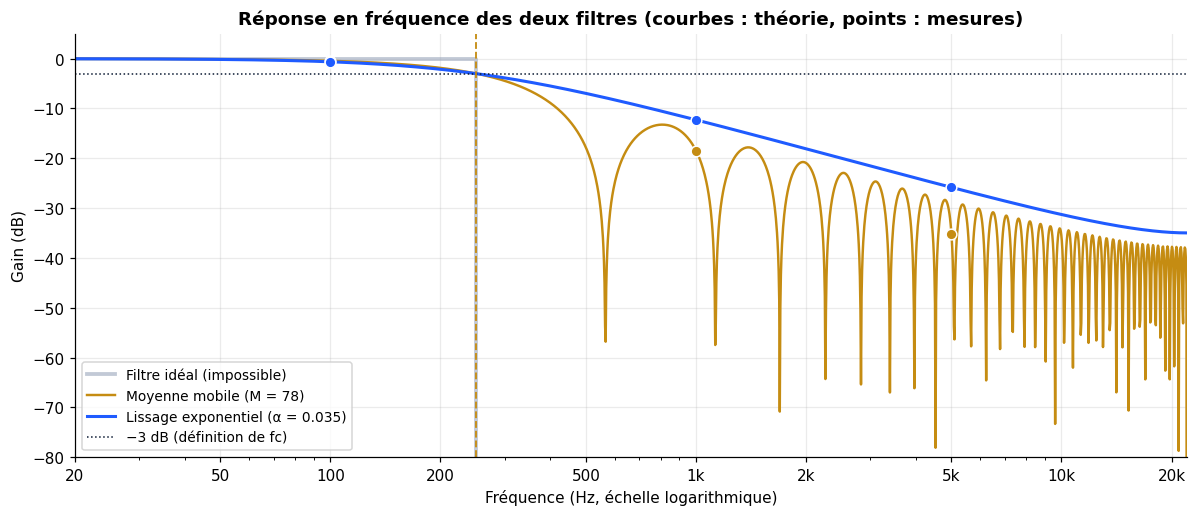

In [9]:
f_axe = np.logspace(np.log10(20), np.log10(FS / 2), 2000)     # 2 000 fréquences de 20 Hz à 22 kHz
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot([20, FC, FC], [0, 0, -80], color=GRIS, lw=2.5, alpha=0.6, label="Filtre idéal (impossible)")
ax.plot(f_axe, en_db(gain_moyenne_mobile(f_axe, M) + 1e-9), color=OR, lw=1.6, label=f"Moyenne mobile (M = {M})")
ax.plot(f_axe, en_db(gain_lissage(f_axe, alpha)), color=BLEU, lw=2, label=f"Lissage exponentiel (α = {alpha:.3f})")
for nom, (freq, A) in COMPOSANTES.items():            # les points mesurés
    ax.plot(freq, en_db(amplitude_a(y_mm, freq) / A), "o", color=OR, ms=7, mec="white")
    ax.plot(freq, en_db(amplitude_a(y_exp, freq) / A), "o", color=BLEU, ms=7, mec="white")
ax.axhline(-3, color=NUIT, ls=":", lw=1, label="−3 dB (définition de fc)")
ax.axvline(FC, color=OR, ls="--", lw=1.2)
axe_frequences(ax)
ax.set(title="Réponse en fréquence des deux filtres (courbes : théorie, points : mesures)", ylabel="Gain (dB)", ylim=(-80, 5))
ax.legend(loc="lower left")
fig.tight_layout()
plt.show()

> **Comment lire le résultat :** - **Les deux filtres coupent bien à 250 Hz** : les courbes croisent la ligne −3 dB exactement à la coupure.
- **Les points tombent sur les courbes** : mesures et théorie concordent.
- **Le lissage exponentiel** (bleu) descend régulièrement, de −6 dB par octave : c'est la pente d'un filtre d'ordre 1. C'est doux, et la médium n'est réduite que d'environ 12 dB : on l'entend encore.
- **La moyenne mobile** (or) descend plus vite au début, puis présente des **rebonds** (des « lobes »). Elle a même des **zéros**, des fréquences totalement supprimées, tous les $f_s / M$ ≈ 565 Hz.
- **Aucun des deux n'approche le filtre idéal** : pour une coupure plus raide, il faudra un filtre d'ordre plus élevé (Butterworth).

### 4.5 À l'écoute

> **Ce que fait la cellule suivante :** elle affiche trois lecteurs : le signal d'origine, puis la sortie de chaque filtre. Écoutez avec un casque : après filtrage, le son est **étouffé**, la note grave domine.

In [10]:
ecouter(x, "Avant (signal de test)")
ecouter(y_mm, "Après moyenne mobile")
ecouter(y_exp, "Après lissage exponentiel")

Avant (signal de test) — crête : 0.61 (-4.2 dBFS)


Après moyenne mobile — crête : 0.31 (-10.3 dBFS)


Après lissage exponentiel — crête : 0.33 (-9.6 dBFS)


## 5. Appliquer un gain à la bande des graves

C'est exactement ce que fera l'égaliseur, en version simplifiée à **deux bandes** :

1. **Isoler les graves** avec le passe-bas : `graves = passe_bas(x)`.
2. Calculer le **reste** : `reste = x − graves`. C'est tout ce que le passe-bas n'a pas gardé.
3. **Appliquer le gain** aux graves, puis **recombiner** : `x_eq = reste + facteur × graves`.

Le gain est donné en décibels et converti en facteur d'amplitude : $\text{facteur} = 10^{G/20}$. Par exemple, +6 dB ≈ ×2 et −6 dB ≈ ×0,5.

> **Ce que fait la cellule suivante :** elle applique ces trois étapes avec le lissage exponentiel et un gain de **+6 dB**. Elle vérifie ensuite deux choses :

- avec un gain de 0 dB, on retrouve **exactement** le signal d'origine (puisque reste + graves = x) ;
- la crête du signal ne dépasse pas 1, sinon il y aurait **écrêtage**.

Changez `G_DB` pour essayer d'autres gains.

In [11]:
def db_vers_facteur(gain_db):
    # dB -> facteur d'amplitude : +6 dB -> ×2 ; −6 dB -> ×0,5 ; 0 dB -> ×1
    return 10 ** (gain_db / 20)


G_DB = 6.0                                    # gain appliqué aux graves (dB) : essayez −6, +3, +12…
facteur = db_vers_facteur(G_DB)

graves = lissage_exponentiel(x, alpha)        # 1. isoler les graves (passe-bas)
reste = x - graves                            # 2. le reste : médiums + aigus
x_eq = reste + facteur * graves               # 3. gain sur les graves, puis recombinaison

print(f"Gain des graves : {G_DB:+.1f} dB, soit une amplitude × {facteur:.3f}")
print("Vérification à 0 dB : on retrouve exactement x ?", np.allclose(reste + db_vers_facteur(0) * graves, x))
print(f"Crête avant : {np.max(np.abs(x)):.3f} — crête après : {np.max(np.abs(x_eq)):.3f}",
      "→ écrêtage !" if np.max(np.abs(x_eq)) > 1 else "→ pas d'écrêtage")

Gain des graves : +6.0 dB, soit une amplitude × 1.995
Vérification à 0 dB : on retrouve exactement x ? True
Crête avant : 0.615 — crête après : 0.905 → pas d'écrêtage


> **Ce que fait la cellule suivante :** elle trace trois graphiques :

1. la **séparation** : le signal, ses graves (bleu) et le reste (violet) ;
2. le signal **avant / après** le gain, avec la limite d'écrêtage (±1) ;
3. les **spectres** avant / après, avec la variation mesurée de chaque note.

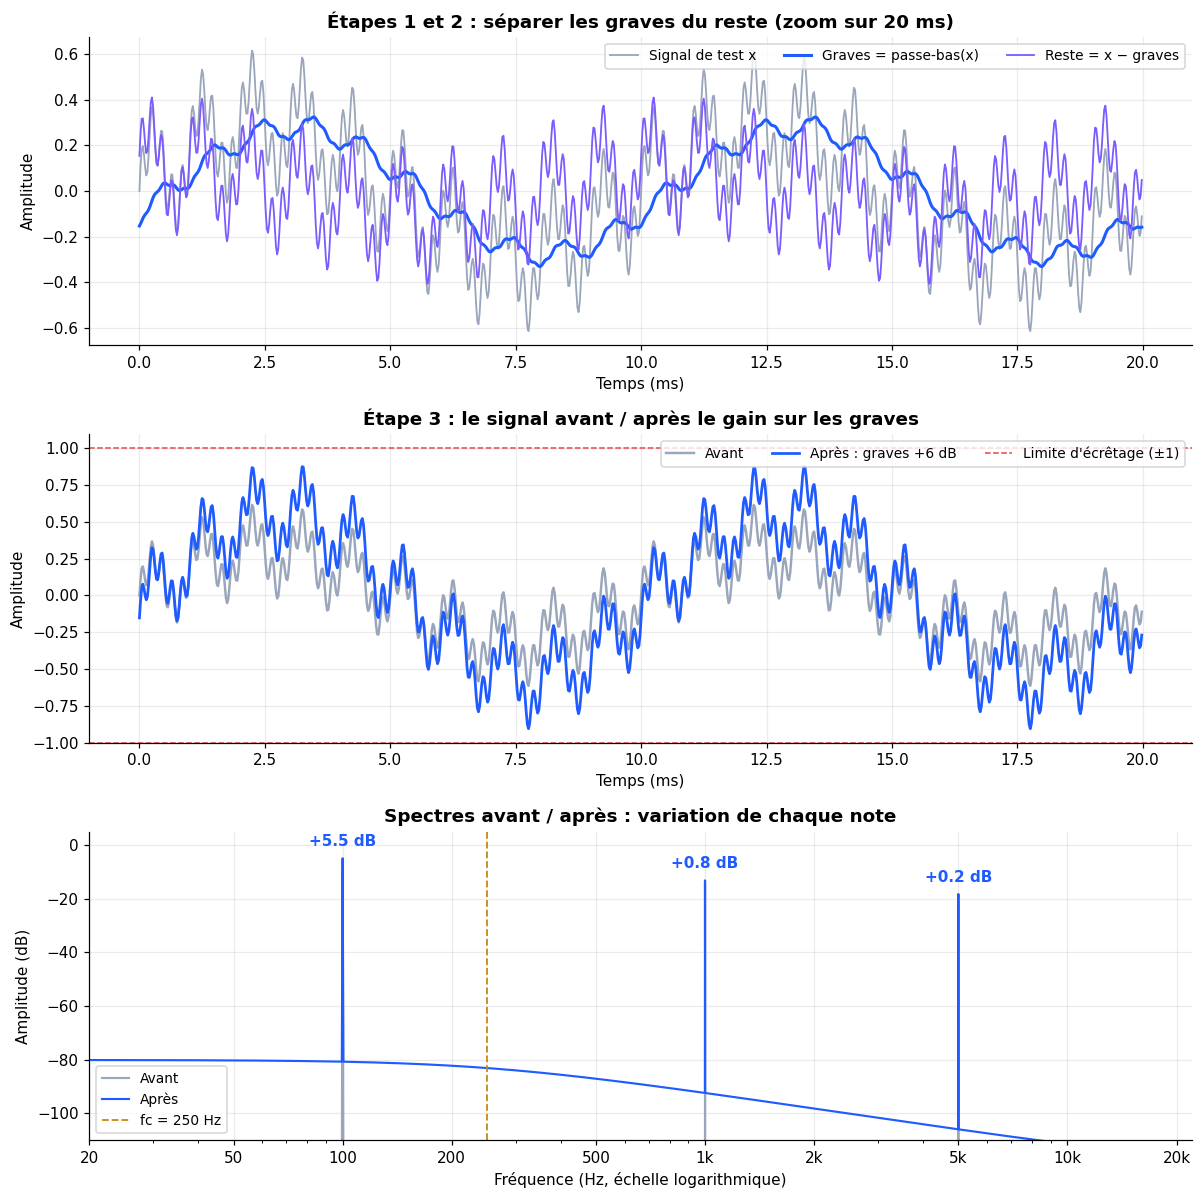

In [12]:
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(11, 11))

# 1. Séparation en deux bandes
ax1.plot(t_ms, x[zoom], color=GRIS, lw=1.2, label="Signal de test x")
ax1.plot(t_ms, graves[zoom], color=BLEU, lw=2, label="Graves = passe-bas(x)")
ax1.plot(t_ms, reste[zoom], color=VIOLET, lw=1.2, label="Reste = x − graves")
ax1.set(title="Étapes 1 et 2 : séparer les graves du reste (zoom sur 20 ms)", xlabel="Temps (ms)", ylabel="Amplitude")
ax1.legend(loc="upper right", ncol=3)

# 2. Avant / après le gain
ax2.plot(t_ms, x[zoom], color=GRIS, lw=1.6, label="Avant")
ax2.plot(t_ms, x_eq[zoom], color=BLEU, lw=1.8, label=f"Après : graves {G_DB:+.0f} dB")
ax2.axhline(1, color="#e5484d", ls="--", lw=1)
ax2.axhline(-1, color="#e5484d", ls="--", lw=1, label="Limite d'écrêtage (±1)")
ax2.set(title="Étape 3 : le signal avant / après le gain sur les graves", xlabel="Temps (ms)", ylabel="Amplitude")
ax2.legend(loc="upper right", ncol=3)

# 3. Spectres avant / après, avec la variation de chaque note écrite au-dessus de son pic
f, db_avant = spectre_db(x)
_, db_apres = spectre_db(x_eq)
ax3.plot(f[1:], db_avant[1:], color=GRIS, lw=1.4, label="Avant")
ax3.plot(f[1:], db_apres[1:], color=BLEU, lw=1.4, label="Après")
for nom, (freq, A) in COMPOSANTES.items():
    variation = en_db(amplitude_a(x_eq, freq) / A)
    ax3.annotate(f"{variation:+.1f} dB", (freq, en_db(amplitude_a(x_eq, freq))), xytext=(0, 8),
                 textcoords="offset points", ha="center", color=BLEU, fontweight="bold")
ax3.axvline(FC, color=OR, ls="--", lw=1.2, label="fc = 250 Hz")
axe_frequences(ax3)
ax3.set(title="Spectres avant / après : variation de chaque note", ylabel="Amplitude (dB)", ylim=(-110, 5))
ax3.legend(loc="lower left")
fig.tight_layout()
plt.show()

> **Comment lire le résultat :** au milieu, la courbe bleue ondule **plus fort** que la grise : c'est la grave amplifiée. En bas, le pic de 100 Hz monte nettement, tandis que ceux de 1 kHz et 5 kHz bougent à peine.

> **Ce que fait la cellule suivante :** elle résume dans un tableau le gain **voulu** et le gain **obtenu** pour chaque note, puis affiche les lecteurs avant / après.

In [13]:
resume = pd.DataFrame([
    {
        "Note": nom,
        "Gain voulu (dB)": G_DB if freq < FC else 0.0,          # +6 dB pour la grave, 0 pour les autres
        "Gain obtenu (dB)": en_db(amplitude_a(x_eq, freq) / A),  # mesuré dans le spectre
    }
    for nom, (freq, A) in COMPOSANTES.items()
]).set_index("Note")
display(resume.style.format("{:+.1f}"))

ecouter(x, "Avant")
ecouter(x_eq, f"Après : graves {G_DB:+.0f} dB")

,Gain voulu (dB),Gain obtenu (dB)
Note,,
Grave 100 Hz,+6.0,+5.5
Médium 1 kHz,+0.0,+0.8
Aigu 5 kHz,+0.0,+0.2


Avant — crête : 0.61 (-4.2 dBFS)


Après : graves +6 dB — crête : 0.91 (-0.9 dBFS)


> **Comment lire le résultat :** le gain obtenu n'est **pas exactement** celui demandé.

- **La grave (100 Hz)** gagne un peu moins que +6 dB. Le passe-bas ne la laisse pas passer à 100 %, et il la **décale légèrement dans le temps** (déphasage) : la copie amplifiée ne s'aligne pas parfaitement sur l'original.
- **La médium (1 kHz)** est légèrement amplifiée, alors qu'on ne le voulait pas. C'est la **zone de transition** : un filtre d'ordre 1 laisse encore passer une partie des 1 kHz dans les « graves », et cette partie reçoit le gain.
- **L'aiguë (5 kHz)**, très loin de la coupure, ne bouge presque pas.

Un filtre **plus raide** (d'ordre plus élevé) réduira ces fuites d'une bande vers l'autre.

## 6. Bilan

| | Moyenne mobile | Lissage exponentiel |
|---|---|---|
| Formule | moyenne des M derniers échantillons | $y[n] = y[n-1] + \alpha\,(x[n] - y[n-1])$ |
| Réglage | longueur M (ici 78) | coefficient α (ici ≈ 0,035) |
| Type | RIF (n'utilise que les entrées) | RII (récursif, réutilise sa sortie) |
| Mémoire | M valeurs | 1 seule valeur |
| Pente | rapide au début, puis rebonds et zéros | régulière, −6 dB par octave |
| Déphasage | retard constant de (M−1)/2 échantillons | retard qui dépend de la fréquence |

**Limites :** ces deux filtres sont d'ordre faible, et leur transition est donc large. Pour EGALIZE, il faudra des pentes plus raides.

## 7. À vous de jouer

Modifiez une valeur, puis relancez tout (**Exécuter tout**) :

1. Passez `FC` à 1 000 Hz. Que devient la note médium après filtrage ?
2. Mettez `G_DB = -6`. Les graves sont-elles bien atténuées ?
3. Mettez `G_DB = 12`. Que dit le contrôle d'écrêtage ? Pourquoi ?
4. Remplacez `lissage_exponentiel` par `moyenne_mobile` dans la partie 5. Lequel des deux donne le gain le plus juste sur la médium ?
5. Ajoutez du bruit au signal de test (`x = x + 0.02 * np.random.randn(len(x))`) et observez ce que le passe-bas en fait.